# SQDMetal two transmons with a λ/2 bus resonator (Quantcore PDK rebuild)

**What the chip is.** sqdlab SQDMetal's `doc-sphinx/source/examples/2_transmons_wRes_comp.ipynb` with the SQDMetal
components `TransmonTaperedInsets`, `Smooth_Capacitor_Semicircle` and `ResonatorMeanderPinPin`
(<https://github.com/sqdlab/SQDMetal>, **Apache-2.0**; spec `docs/designs/sqdmetal/2_transmons_wres_comp.md`).
Stored outputs: a layout plot, a Palace capacitance matrix and derived circuit parameters (5 × 2 mm chip, silicon
280 µm). Two floating tapered-pad transmons, each capacitively coupled through a semicircular "smooth" capacitor
on its inner top pad corner to one 8.96 mm λ/2 meander bus between them (6.8 GHz on Si). No feedline: a
bus-coupling study. Stated: f_q 4.5 GHz (L_J 13.203 / 13.196 nH), E_C ≈ 225 MHz, g ≈ 83 MHz, f_res 6.8 GHz.

This notebook **rebuilds** it with our components, routes, netlist and LOM on the Quantcore PDK (not a replica);
we distribute the rebuild under GPL-3.0.

| topic | SQDMetal source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 5 × 2 mm chip centred on (0, 0) | the 7.5 × 7.5 mm Quantcore die with its frame, device ID "SQD-2TR" |
| pads | none (Palace ports on the junctions; a bus-coupling study) | none: nothing for the pad rule (`frame.pad_edge`, 100 µm) |
| substrate | silicon, 280 µm | sapphire 650 µm, εr 10.25 |
| junctions | L_J 13.203 / 13.196 nH for 4.5 GHz (a junction line) | Quantcore trilayer junctions **sized for the stated 4.5 GHz**: 0.34 × 0.6 µm, L_J ≈ 9.9 nH — R_n ≈ 66 kΩ, ⚠ above the 40–50 kΩ window (a 45 kΩ junction would give ≈ 5.4 GHz) |
| cheese | none (`cap_sim.add_ground_plane()` without holes, a Gmsh mesh for Palace) | the PDK band (chip `cheese` `"auto"`, at least 4 µm clear of 3/0) |
| components | `TransmonTaperedInsets` × 2, `Smooth_Capacitor_Semicircle` × 2, `ResonatorMeanderPinPin` | Quantcore re-implementations of the two SQDMetal cells (Apache-2.0) with the source options; the bus as a qcc meander route |
| placement | Q1 at −1.25 mm, Q2 at +1.65 mm (the layout is 200 µm east of its chip centre) | centred in the die: everything 200 µm west (Designer = source + (2300, 1000) µm) |

**Changed / estimated (kept from the earlier rebuild):**
- **`chrgln_pin_y_offset` +10 µm instead of the source's −10 µm.** With −10 the SQDMetal formulas put the
  capacitor's bite 10 µm off the pad end, so the capacitor overlaps the qubit pad (a short; components' finding,
  `test_semicircle_capacitor_on_the_qubit_pin[-10]`), while the stored plot and the Palace C-matrix show two
  separate conductors. 0 puts the pin exactly on the pocket edge (DRC open/short errors there); +10 is the other
  value consistent with the stored outputs: 4–15 µm gap, no overlap, a 20 µm lead to the pocket edge.
- **Bus length:** `ResonatorMeanderPinPin` runs 8960 µm from pin `a`, 25 µm (`gap_front`) inside each pad's back
  edge; our route runs between the ports `a` at the pocket edges, so it is 8960 − 2 × (25 + 20) = 8870 µm (the same
  physical line). The meander is KQC's (12 turns).
- **LOM capacitances** are lom's analytic estimates (pads 126 fF to ground, 37 fF pad–pad, capacitor 25 fF to the
  pad); the source's Palace values are 73.5 / 79.7 fF, 35.7 fF and 17.6 fF, so f_q and E_C differ from the source.

## 1 · Setup

`LIVE` follows `QCC_LIVE` (default on: KLayout opens and redraws after every change; `QCC_LIVE=0` for batch
runs). `RUN_FEM = False` keeps the FEM step at "export only"; set it to `True` to solve the jobs in a new batch
AEDT 2024 R1 (if one is installed). `FULL_FAB = False` skips the fab-only corner rounding in the mask step
(`qcc mask` writes the complete file). Step snapshots go to `build/snapshots/` (not kept in the repo); the final
ones next to the notebook.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
RUN_FEM = False                                  # True: solve the exported jobs in a new batch AEDT 2024 R1
FULL_FAB = False                                 # True: also round the corners in the fab export
OUT = Path("examples/designs") / "sqdmetal"        # design JSON + final snapshots
STEPS = Path("build/snapshots") / "2_transmons_wres_comp"       # step-by-step snapshots (build/ is not kept in the repo)
X0, Y0 = 2500, 1000                              # Metal's 5 × 2 mm chip is centred on (0, 0)

## 2 · The PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and every FEM export, the frame and the pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

**The junctions from the PDK rule.** The stated target is f_q 4.5 GHz for both qubits. `size_junction(4.5, C_Σ)`
solves the trilayer junction on the PDK rule for each qubit's C_Σ (≈ 107 fF without the junction, from this
design's LOM before the rebuild: f_q 4.06 GHz with the source's 13.2 nH, C_J 0): straight fingers 0.34 µm ×
0.6 µm, L_J ≈ 9.9 nH, C_J ≈ 10.2 fF — **R_n ≈ 66 kΩ, above the 40–50 kΩ window**; the sizing lines print the
note. Kept: the target is the source's. `trilayer_junction` turns L_J into the cell's `junction_type` +
`junction_params` and the LOM junction.

In [4]:
from quantcore_circuits.circuit.bridges import size_junction
JJ_PARAMS, JUNCTION = {}, {}
for q, c in (("Q1", 106.7), ("Q2", 106.5)):
    s = size_junction(4.5, c, c_includes_junction=False)
    JJ_PARAMS[q], JUNCTION[q] = trilayer_junction("TransmonTaperedInsets", lj_nH=s.lj_nH)
    print(q, JUNCTION[q], f"R_n {s.rn_kohm:.0f} kΩ, fingers {s.finger_width} × {s.second_finger_width} µm;", *s.notes)

Q1 {'Lj_nH': 9.9036, 'Cj_fF': 10.2} R_n 67 kΩ, fingers 0.34 × 0.6 µm; R_n 66.5 kΩ is outside the process window 40–50 kΩ (f_q 4.5 GHz with C_Σ 116.8 fF needs E_J/h 16.4 GHz)
Q2 {'Lj_nH': 9.9036, 'Cj_fF': 10.2} R_n 67 kΩ, fingers 0.34 × 0.6 µm; R_n 66.7 kΩ is outside the process window 40–50 kΩ (f_q 4.5 GHz with C_Σ 116.6 fF needs E_J/h 16.4 GHz)


## 3 · The die and its frame

`Designer(name, box=...)` opens the die: the 7.5 × 7.5 mm Quantcore die placed so the source's 5 × 2 mm area sits
in its middle (source + (2500, 1000) µm; the centring step below moves the content a further 200 µm west). The
PDK frame: L dicing markers (1000/0), 3 × 3 alignment grids (1001/0), the chip boundary (100/0), the device ID on
a free edge. The chip `cheese` stays `"auto"`: the source has no cheese, so the PDK band is drawn.

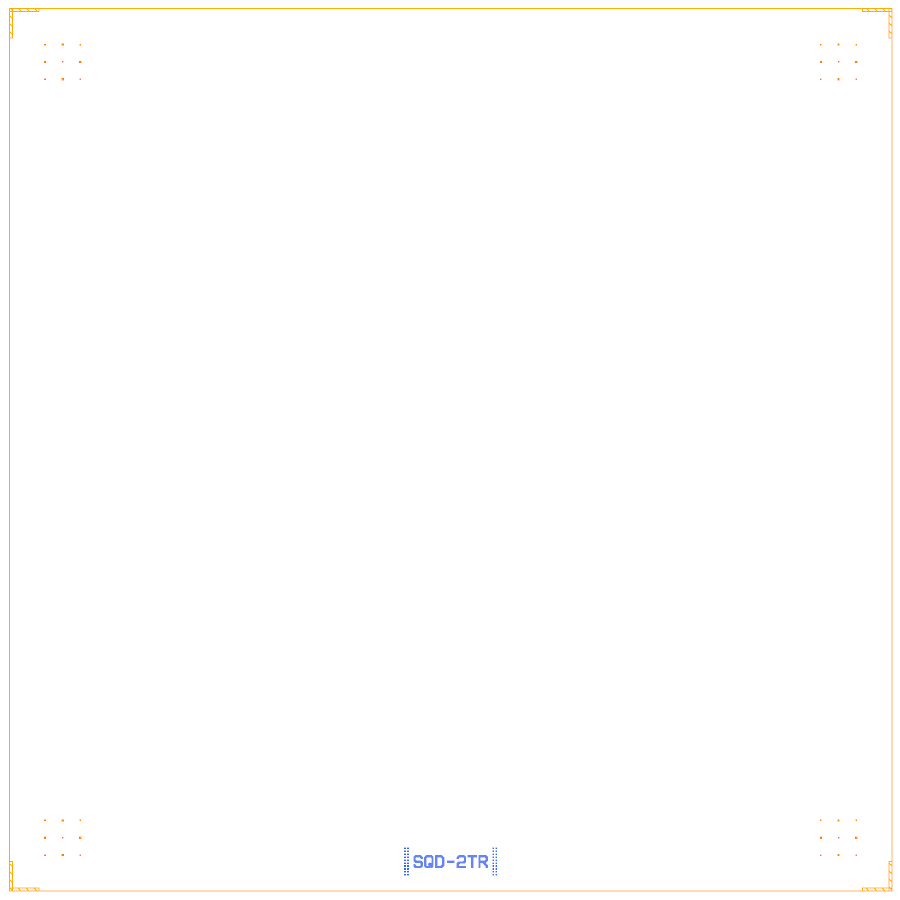

In [5]:
d = Designer("2_transmons_wres_comp", box=(-1250, -2750, 6250, 4750), chip={"name_chip": "SQD-2TR"}, live=LIVE)
snap(d, STEPS / "1_die.png", size=(900, 900), width=360);

## 4 · Pads and the pad rule

**PDK rule:** a bond pad's or launcher's outer etch edge sits `frame.pad_edge` (100 µm) from the die edge
(`edge="auto"`). The source is a capacitance / bus-coupling study with no pads or launchers (its only ports are
the junctions), so there is nothing to place here and the table is empty.

In [6]:
display(Markdown(pads_md(d)))

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| – | no bond pads or launchers | – | – | – |

## 5 · Components

**Qubits:** `TransmonTaperedInsets` (Quantcore re-implementation of SQDMetal's, Apache-2.0) with the source
options: orientation 0, pocket 1000 × 420 µm, `pocket_lower_tighten` 0, `chrgln_pin_x_offset` 0 and
`chrgln_pin_y_offset` +10 (see above); SQDMetal defaults otherwise: 800 × 110 µm pads 100 µm apart, 40 µm tapers
to a 20 µm gap where the trilayer junction is drawn (`junction_params`). Ports: the placement pins
(`top_left_pin`, `top_right_pin`, `bottom_*_pin`, `*_pocket_pin`) and the junction points `squid_a` / `squid_b`.

**Capacitors:** `SmoothCapacitorSemicircle` (re-implementation of `Smooth_Capacitor_Semicircle`) with the source
options — 160 × 80 µm pad, 60 µm semicircle, fillet 5 µm, resolution 20, orientation 180 / 0 — **snapped** to
`Q1.top_right_pin` / `Q2.top_left_pin` (`snap="target"`, `to=...`): the capacitor follows the qubit. Its port `a`
starts the bus.

<TransmonTaperedInsets Q1 ports=['bottom_left_pin', 'bottom_pocket_pin', 'bottom_right_pin', 'squid_a', 'squid_b', 'top_left_pin', 'top_pocket_pin', 'top_right_pin']>
<SmoothCapacitorSemicircle C1 ports=['a', 'target']>


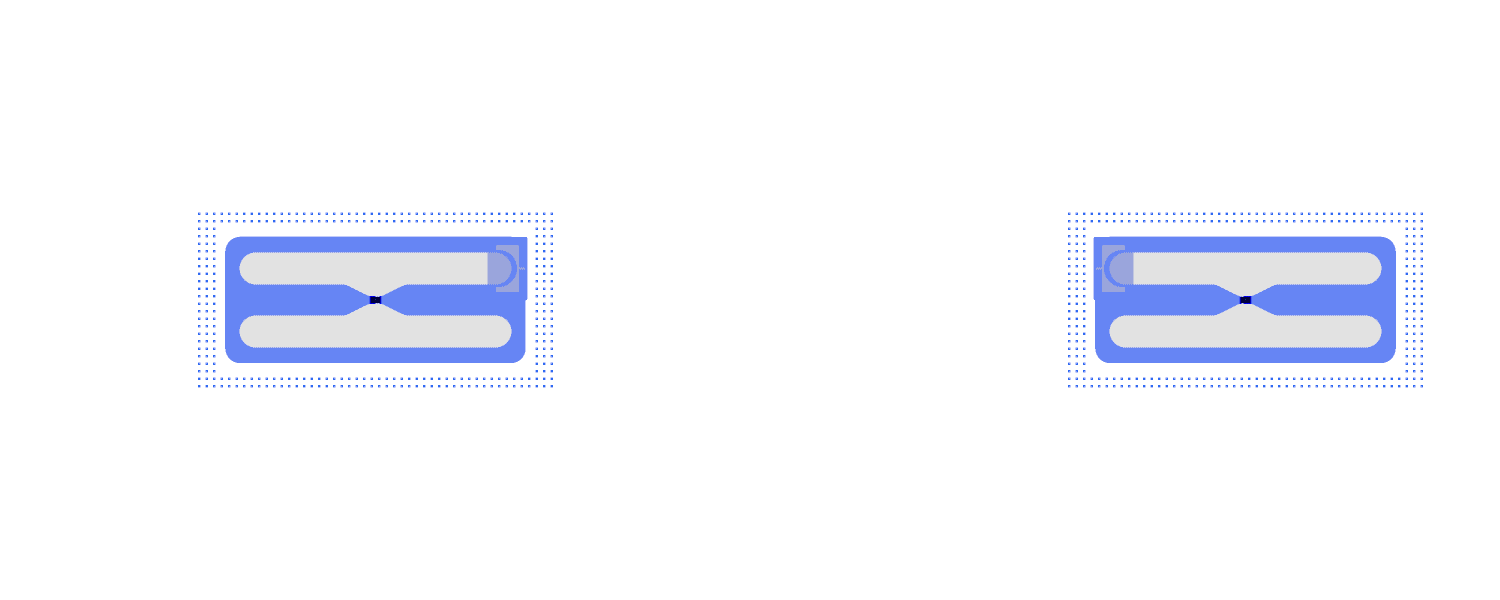

In [7]:
PIN_OFF = 10                                     # chrgln_pin_y_offset: source −10 overlaps the qubit pad (see above)
TTI = dict(pocket_height=420, pocket_lower_tighten=0, chrgln_pin_x_offset=0, chrgln_pin_y_offset=PIN_OFF)
CAP = dict(rect_width=160, rect_length=80, semi_radius=60, fillet_radius=5, fillet_resolution=20,
           lead_length=30 - PIN_OFF)             # lead from the pad's back edge to the pocket edge
with d.batch():
    q1 = d.add("Q1", "TransmonTaperedInsets", at=(X0 - 1250, Y0), junction=JUNCTION["Q1"], **JJ_PARAMS["Q1"], **TTI)
    q2 = d.add("Q2", "TransmonTaperedInsets", at=(X0 + 1650, Y0), junction=JUNCTION["Q2"], **JJ_PARAMS["Q2"], **TTI)
    c1 = d.add("C1", "SmoothCapacitorSemicircle", snap="target", to=q1.top_right_pin, orientation=180, **CAP)
    c2 = d.add("C2", "SmoothCapacitorSemicircle", snap="target", to=q2.top_left_pin, orientation=0, **CAP)
print(q1, c1, sep="\n")
snap(d, STEPS / "2_components.png", box=(X0 - 2500, Y0 - 1000, X0 + 2500, Y0 + 1000), size=(1500, 600), width=600);

## 6 · Routes

**The bus** between the two capacitors' ports `a`: a meander of 8870 µm (the source's 8960 µm counted from SQDMetal's
pin `a` inside each pad, minus 2 × (25 + 20) µm), KQC's meander with 12 turns, r = 40 µm, CPW 10/6 µm.

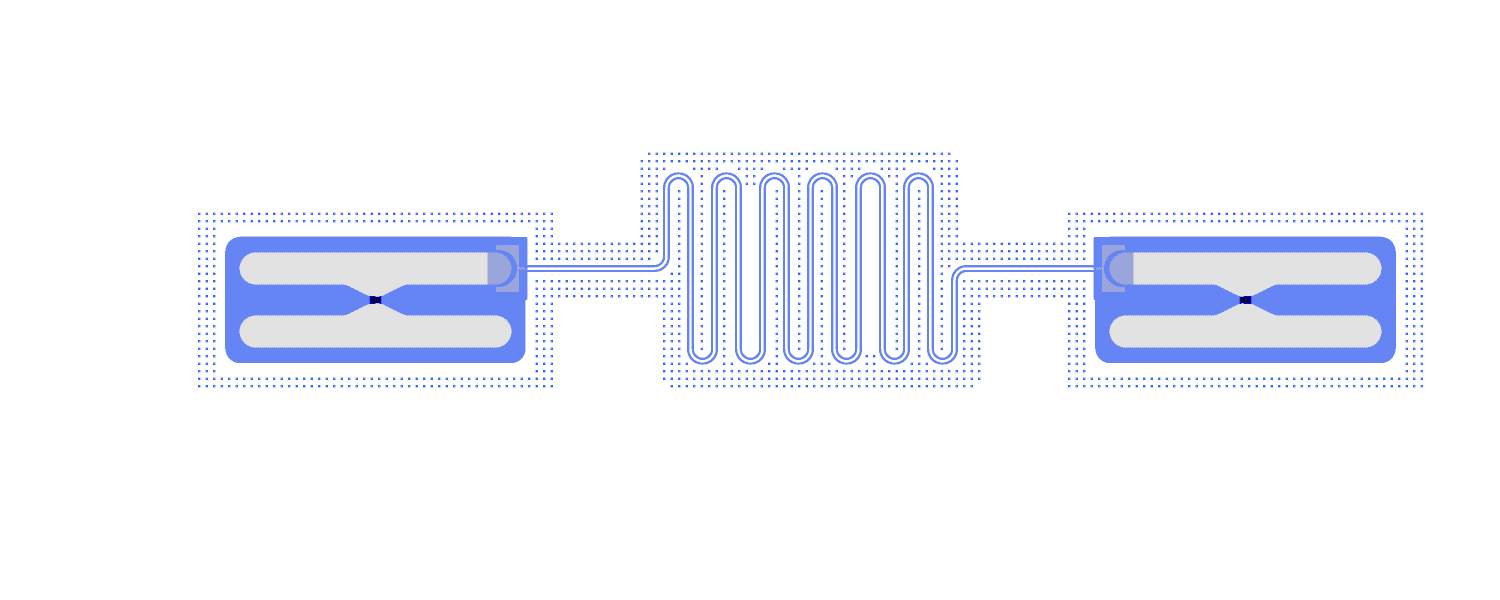

BUS 8870.0 µm


In [8]:
PIN_A_INSET = 25.0                               # SQDMetal pin a: gap_front (25 µm) inside the pad's back edge
L_BUS = 8960 - 2 * (PIN_A_INSET + CAP["lead_length"])   # route between the two ports a (source total from pin a)
d.route("BUS", c1.a, c2.a, meander=L_BUS, r=40).set(meanders=12)
snap(d, STEPS / "3_routes.png", box=(X0 - 2500, Y0 - 1000, X0 + 2500, Y0 + 1000), size=(1500, 600), width=600)
print("BUS", round(d.result.route_lengths()["BUS"], 1), "µm")

**Targets, sim group, centring, save.** The stated targets (f_q 4.5 GHz, bus 6.8 GHz on silicon) go into the
design; one sim group holds the whole circuit (a Q3D C-matrix — the source's own analysis — and an eigenmode / EPR
job). `center_in_die` applies the PDK placement rule: the source's layout sits 200 µm east of its own chip
centre (Q1 at −1.25 mm, Q2 at +1.65 mm), so the content moves 200 µm west (the capacitors follow their snaps, the
bus its ports). Then the design is saved.

In [9]:
d.targets(Q1={"f_q_GHz": 4.5}, Q2={"f_q_GHz": 4.5}, BUS={"f_GHz": 6.8})
d.sim_group("ALL", ["Q1", "Q2", "C1", "C2", "BUS"])
DX, DY = center_in_die(d)
print("centring shift (µm):", (DX, DY))
rebuild(d)
DESIGN = d.save(OUT / "2_transmons_wres_comp.json")
print(d, "→", DESIGN, "| BUS", round(d.result.route_lengths()["BUS"], 1), "µm")

centring shift (µm): (-200.0, 0.0)
<Designer 2_transmons_wres_comp: 4 instances, 1 routes, live=False> → examples\designs\sqdmetal\2_transmons_wres_comp.json | BUS 8870.0 µm


## 7 · DRC
The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab; there must be none. **Warnings** are connectivity or geometry notes
to read (often by design). **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`) flag values outside
the PDK margins: flagged, never enforced — the rebuild keeps the source's choices. `pdk_report(d)` sums up the PDK
side: the cheese source, the content centre against the die centre, the junction types and the design warnings.
Expected here: **no errors**; `dangling_port` warnings for the unused `TransmonTaperedInsets` placement pins
(`top_left_pin` of Q1, `top_right_pin` of Q2, the `bottom_*_pin` and `*_pocket_pin`: SQDMetal's marks for charge
lines or capacitors, not CPW ends) and the junction points `squid_a` / `squid_b`. PDK design warnings: `pdk_rn` on
both qubits (R_n ≈ 66 kΩ, sized for the stated 4.5 GHz; flagged, not retuned).

In [10]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

**0 errors · 14 warnings · 2 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 14 | Q1.bottom_left_pin is not connected (no route or snap) |
| PDK design warning | `pdk_rn` | 2 | Q1: junction R_n 66.2 kΩ is outside the PDK window 40–50 kΩ (L_J 9.9036 nH) |

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Junction × 2 |
| PDK design warnings | 2 (pdk_rn × 2) |
| pdk_rn | Q1: junction R_n 66.2 kΩ is outside the PDK window 40–50 kΩ (L_J 9.9036 nH) |
| pdk_rn | Q2: junction R_n 66.2 kΩ is outside the PDK window 40–50 kΩ (L_J 9.9036 nH) |

## 8 · Netlist and LOM

`d.lom()` maps the ports onto circuit nodes. Each `TransmonTaperedInsets` is a floating transmon: two pad nodes
(`island1`, `island2`) with C to ground and between them, the junction across them. Each semicircle capacitor is a
C from the qubit's top pad to its port node; the bus between the two capacitor ports is a λ/2 `TLres` (capacitive at
both ends). The netlist lists the unused placement pins as unconnected (nothing attaches there).

In [11]:
lb = d.lom()
show_netlist(lb)
display(Markdown("**C1 / C2 / BUS ports → circuit nodes:**\n\n| port | node |\n|---|---|\n" + "\n".join(
    f"| `{ref}` | `{node}` |" for ref, node in sorted(lb.port_map.items()) if ref.startswith(("C1.", "C2.", "BUS", "Q1.top_right", "Q2.top_left")))))

**6 nodes · 13 branches · 0 controls · 10 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `Q1.island1` | `Q1.island1`, `C1.target` |
| `Q1.island2` | `Q1.island2` |
| `Q2.island1` | `Q2.island1`, `C2.target` |
| `Q2.island2` | `Q2.island2` |
| `C1.pad` | `C1.pad`, `C2.pad` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `C_Q1_1` | C | `Q1.island1` – `gnd` | 126 fF |
| `C_Q1_2` | C | `Q1.island2` – `gnd` | 126 fF |
| `C_Q1_12` | C | `Q1.island1` – `Q1.island2` | 37.3 fF |
| `J_Q1` | JJ | `Q1.island1` – `Q1.island2` | Lj 9.9 nH, Cj 10.2 fF |
| `C_Q2_1` | C | `Q2.island1` – `gnd` | 126 fF |
| `C_Q2_2` | C | `Q2.island2` – `gnd` | 126 fF |
| `C_Q2_12` | C | `Q2.island1` – `Q2.island2` | 37.3 fF |
| `J_Q2` | JJ | `Q2.island1` – `Q2.island2` | Lj 9.9 nH, Cj 10.2 fF |
| `C_C1` | C | `C1.pad` – `Q1.island1` | 25 fF |
| `C_C1_pad` | C | `C1.pad` – `gnd` | 34 fF |
| `C_C2` | C | `C1.pad` – `Q2.island1` | 25 fF |
| `C_C2_pad` | C | `C1.pad` – `gnd` | 34 fF |
| `BUS` | TLres | `C1.pad` – `gnd` | lambda/2, 8870 µm, 7.105 GHz |

**Unconnected ports:** `Q1.bottom_left_pin`, `Q1.bottom_pocket_pin`, `Q1.bottom_right_pin`, `Q1.top_left_pin`, `Q1.top_pocket_pin`, `Q2.bottom_left_pin`, `Q2.bottom_pocket_pin`, `Q2.bottom_right_pin`, `Q2.top_pocket_pin`, `Q2.top_right_pin`

**C1 / C2 / BUS ports → circuit nodes:**

| port | node |
|---|---|
| `C1.a` | `C1.pad` |
| `C1.target` | `Q1.island1` |
| `C2.a` | `C1.pad` |
| `C2.target` | `Q2.island1` |
| `Q1.top_right_pin` | `Q1.island1` |
| `Q2.top_left_pin` | `Q2.island1` |

## 9 · LOM simulation

QuCat normal modes of the whole circuit and the QuTiP-dressed values next to the stated targets (f_q 4.5 GHz,
bus 6.8 GHz — on silicon; on sapphire the bus lands a little lower). The two qubits are sized identically, so they
hybridise through the bus (participations ≈ 0.5 / 0.5): the per-qubit α and the ZZ are then not meaningful (the
ZZ table says "hybridised"), and the mode table's A column is the per-mode anharmonicity of the pair. Expected:
f_q ≈ 4.7 GHz, bus ≈ 6.6 GHz; f_q sits a little above the target because the sizing used the pre-rebuild C_Σ and
the drawn junction adds its own C_J. The coupling g follows from the splitting of the two qubit modes (≈ Δf / 2,
the qubits being degenerate).

In [12]:
res = simulate_lom(lb, d.design, max_modes=3)
display(Markdown(modes_md(res)))
display(Markdown(summary_md(res, {"Q1": {"f_q_GHz": 4.5}, "Q2": {"f_q_GHz": 4.5}, "BUS": {"f_GHz": 6.8}})))
display(Markdown(zz_md(res)))
qm = [m for m in res.modes if m.kind == "qubit"]
print(f"qubit-qubit splitting {abs(qm[1].f_GHz - qm[0].f_GHz) * 1e3:.1f} MHz (bus-mediated, degenerate qubits)")

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q1 | qubit | 4.6846 | 0 | 82.1 | J_Q2 0.50, J_Q1 0.50 |
| Q2 | qubit | 4.6919 | 0 | 83.4 | J_Q2 0.50, J_Q1 0.50 |
| BUS | resonator | 6.5663 | 0 | 0.0 | BUS 0.99 |

| parameter | LOM (QuTiP) | target |
|---|---|---|
| `Q1.f_q_GHz` | 4.5125 | 4.5 |
| `Q1.alpha_MHz` | -175.82 | – |
| `BUS.chi_MHz` | -1.2394 | – |
| `Q2.f_q_GHz` | 4.5185 | 4.5 |
| `Q2.alpha_MHz` | -5.8781 | – |
| `BUS.f_GHz` | 6.5649 | 6.8 |
| `BUS.kappa_MHz` | 0 | – |

| group | pair | ZZ (kHz) | neighbours | hybridised |
|---|---|---|---|---|
|  | Q1-Q2 | – | yes | yes |

qubit-qubit splitting 7.3 MHz (bus-mediated, degenerate qubits)


## 10 · FEM: send the jobs
The LOM uses analytic capacitance estimates; a finite-element job measures them. `send_fem_jobs` cuts each sim group
out of the chip (its margin), puts ports where lines leave the box, makes each junction a lumped port and writes one
job folder per group and analysis under `build/jobs/` (the group's own analyses: a Q3D C-matrix and an eigenmode /
EPR job). Simulation exports never have cheese; airbridges are dropped unless asked for. The table lists each job's
ports and C-matrix nets (named after the islands, pads and routes, so the results map back onto the LOM nodes).

With `RUN_FEM = True` and AEDT 2024 R1 (or later) installed, each Ansys job is solved in a **new batch,
non-graphical** AEDT (`solve_job`) — an AEDT window you have open is never touched. The command-line equivalent is
`qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).
**Known export limit (reported to components):** the junction ports' reference points land inside the 20 µm
taper-tip gap, with no metal edge there; KQC logs "Unable to create polygon for port" and each qubit's two pads
end up on one excitation (the nets list `Q1.island1` but no `Q1.island2`). So this C-matrix job cannot yet
reproduce the source's pad-to-pad 35.7 fF.

In [13]:
jobs = send_fem_jobs(DESIGN, run=RUN_FEM)
display(Markdown(jobs_md(jobs)))

2 job(s) exported; RUN_FEM is False, nothing solved.


| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| ALL · eigenmode_epr | `build/jobs/2_transmons_wres_comp_ALL_eigenmode_epr` | 1 · junction · `Q1.junction`<br>2 · junction · `Q2.junction` | `Q1.island1`, `Q2.island1`, `Q1.island2`, `Q2.island2`, `C1.pad`, `C2.pad`, `Q1.island1#2` |
| ALL · q3d_cmatrix | `build/jobs/2_transmons_wres_comp_ALL_q3d_cmatrix` | 1 · junction · `Q1.junction`<br>2 · junction · `Q2.junction`<br>3 · waveguide · `C1.a`<br>4 · waveguide · `C2.a` | `Q1.island1`, `Q2.island1`, `C1.a`, `C2.a`, `Q1.island2`, `Q2.island2`, `C1.pad`, `C2.pad` |

## 11 · Bring the results back

When a job has been solved its folder holds `results/results.json`. `fem_back` then calls `fill(model, design, job)`:
the C-matrix replaces the component estimates branch by branch (matched by net name), and the table compares the two;
`simulate(filled)` re-runs the LOM on the extracted values. Until a solve has run, the cell says which jobs are still
waiting.

In [14]:
filled, md = fem_back(lb.model, DESIGN, jobs)
display(Markdown(md))
if filled:
    from quantcore_circuits.lom.simulate import simulate
    key, fc = next(iter(filled.items()))
    display(Markdown(f"**LOM on the FEM values ({key}):**\n\n" + modes_md(simulate(fc, max_modes=2))))

No FEM results yet for ALL · eigenmode_epr, ALL · q3d_cmatrix: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 12 · Change one property and re-simulate

Shorten the bus from 8870 to 8400 µm: its λ/2 mode rises by ≈ 5 % (≈ +0.35 GHz), moving away from the qubits, so
the bus-mediated qubit–qubit splitting shrinks. Done on a copy (`design_copy`), so `2_transmons_wres_comp.json`
keeps the source's length.

In [15]:
d2 = design_copy(DESIGN)
d2["BUS"].set(meander=8400)
after = simulate_lom(d2.lom(), d2.design, max_modes=3)
display(Markdown("**BUS: 8870 → 8400 µm**\n\n" + params_delta_md(res, after)))
for name, r in (("before", res), ("after", after)):
    qm = [m for m in r.modes if m.kind == "qubit"]
    bus = next(m for m in r.modes if m.kind == "resonator")
    print(f"{name}: bus {bus.f_GHz:.4f} GHz, qubit splitting {abs(qm[1].f_GHz - qm[0].f_GHz) * 1e3:.1f} MHz")

**BUS: 8870 → 8400 µm**

| parameter | before | after | Δ |
|---|---|---|---|
| `Q1.f_q_GHz` | 4.5125 | 4.5132 | +0.0007694 |
| `Q1.alpha_MHz` | -175.82 | -176.74 | -0.9166 |
| `BUS.chi_MHz` | -1.2394 | -1.0609 | +0.1785 |
| `Q2.f_q_GHz` | 4.5185 | 4.5185 | -2.005e-06 |
| `Q2.alpha_MHz` | -5.8781 | -5.1437 | +0.7344 |
| `BUS.f_GHz` | 6.5649 | 6.9024 | +0.3375 |
| `BUS.kappa_MHz` | 0 | 0 | +0 |

before: bus 6.5663 GHz, qubit splitting 7.3 MHz
after: bus 6.9036 GHz, qubit splitting 6.3 MHz


## 13 · Build and export

**The design file.** `2_transmons_wres_comp.json` (saved in step 6) is the whole design:
`qcc build examples/designs/sqdmetal/2_transmons_wres_comp.json` rebuilds `build/2_transmons_wres_comp.oas` + its
sidecar, and the KLayout plugin, `qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the filled 3/0
keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese hole), the trilayer junction fingers 2/0 + 4/0 and spacer 50–53/0, and the frame (100/0, 1000/0, 1001/0).
**Cheese:** the source has none (a Gmsh mesh with a plain ground plane), so the PDK band stands — drawn in the
build (`cheese_source` `build`), at least 4 µm clear of 3/0. Corner rounding is fab-only (`FULL_FAB`);
`qcc mask examples/designs/sqdmetal/2_transmons_wres_comp.json` writes the complete file.

In [16]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 1427 |
| 2/0 | JJ_STRAIGHT | 2 |
| 3/0 | M3 | 1423 |
| 4/0 | JJ_BENT | 2 |
| 50/0 | HSQ | 4 |
| 51/0 | SPACER_1 | 4 |
| 52/0 | SPACER_2 | 4 |
| 53/0 | SPACER_3 | 4 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 1419 holes on the mask.

→ `build/2_transmons_wres_comp_fab.oas`

**Simulation export options.** A simulation export never has cheese; airbridges are dropped unless
`airbridges=True` (or the sim group's `settings={"airbridges": True}`). `setup.geometry` says what the export
left out (this chip has no airbridges).

In [17]:
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "ALL", "q3d_cmatrix", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

airbridges=False: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'dropped'}


airbridges=True: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'kept'}


## 14 · Snapshots

The source's 5 × 2 mm area (compare the source's layout plot); Q1 with its semicircle capacitor; its trilayer
junction in the taper-tip gap; the capacitor around the pad end; the die frame's south-west corner (dicing L on
1000/0, 3 × 3 alignment grid on 1001/0); and Q1 in the **fab view** (the mask from step 13: 1/0 with the PDK
cheese band, the 3/0 keep-out, the junction layers). In the layout snapshots the chip boundary 100/0 is drawn as an
outline and the cheese band (KQC's ground-grid layer) is visible; the fab view shows the mask itself.

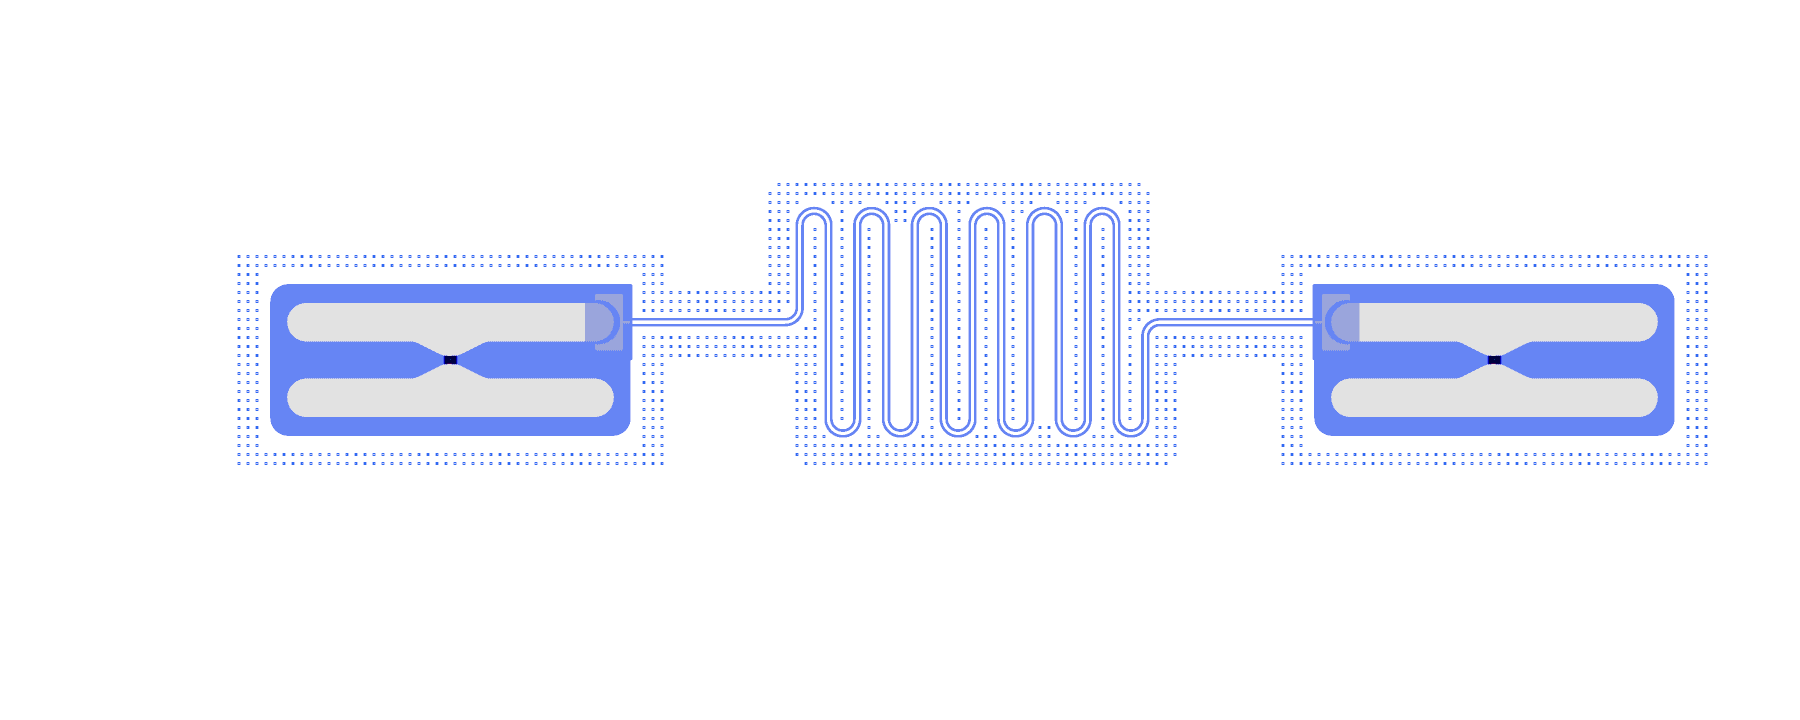

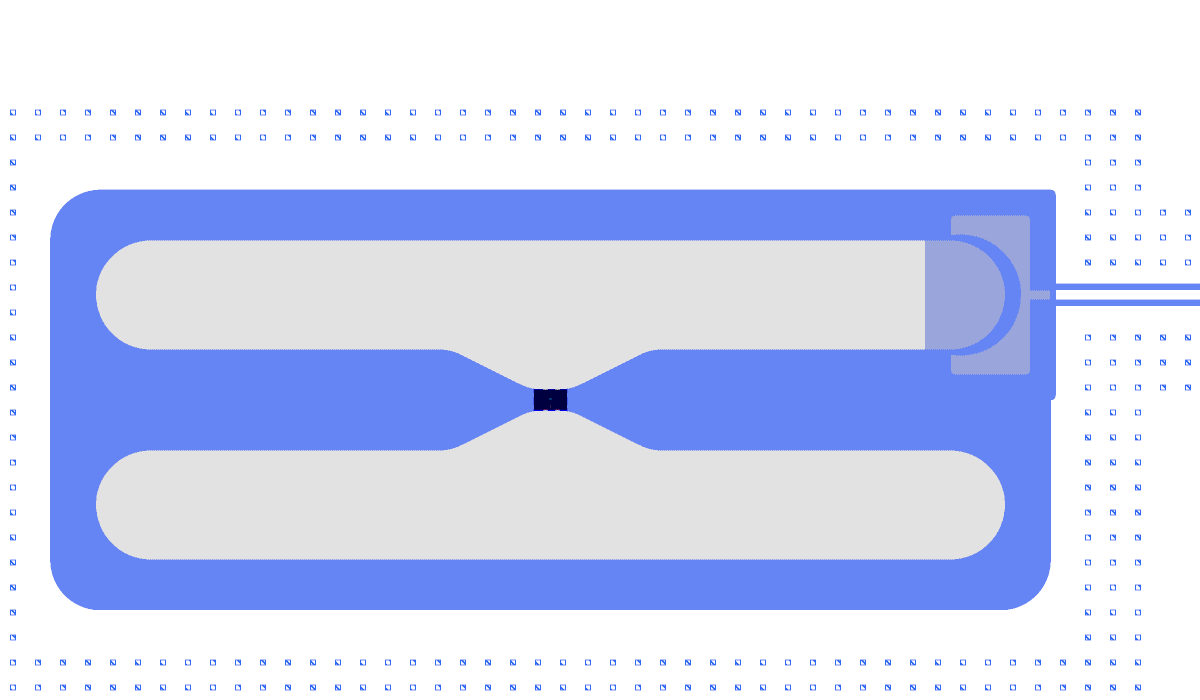

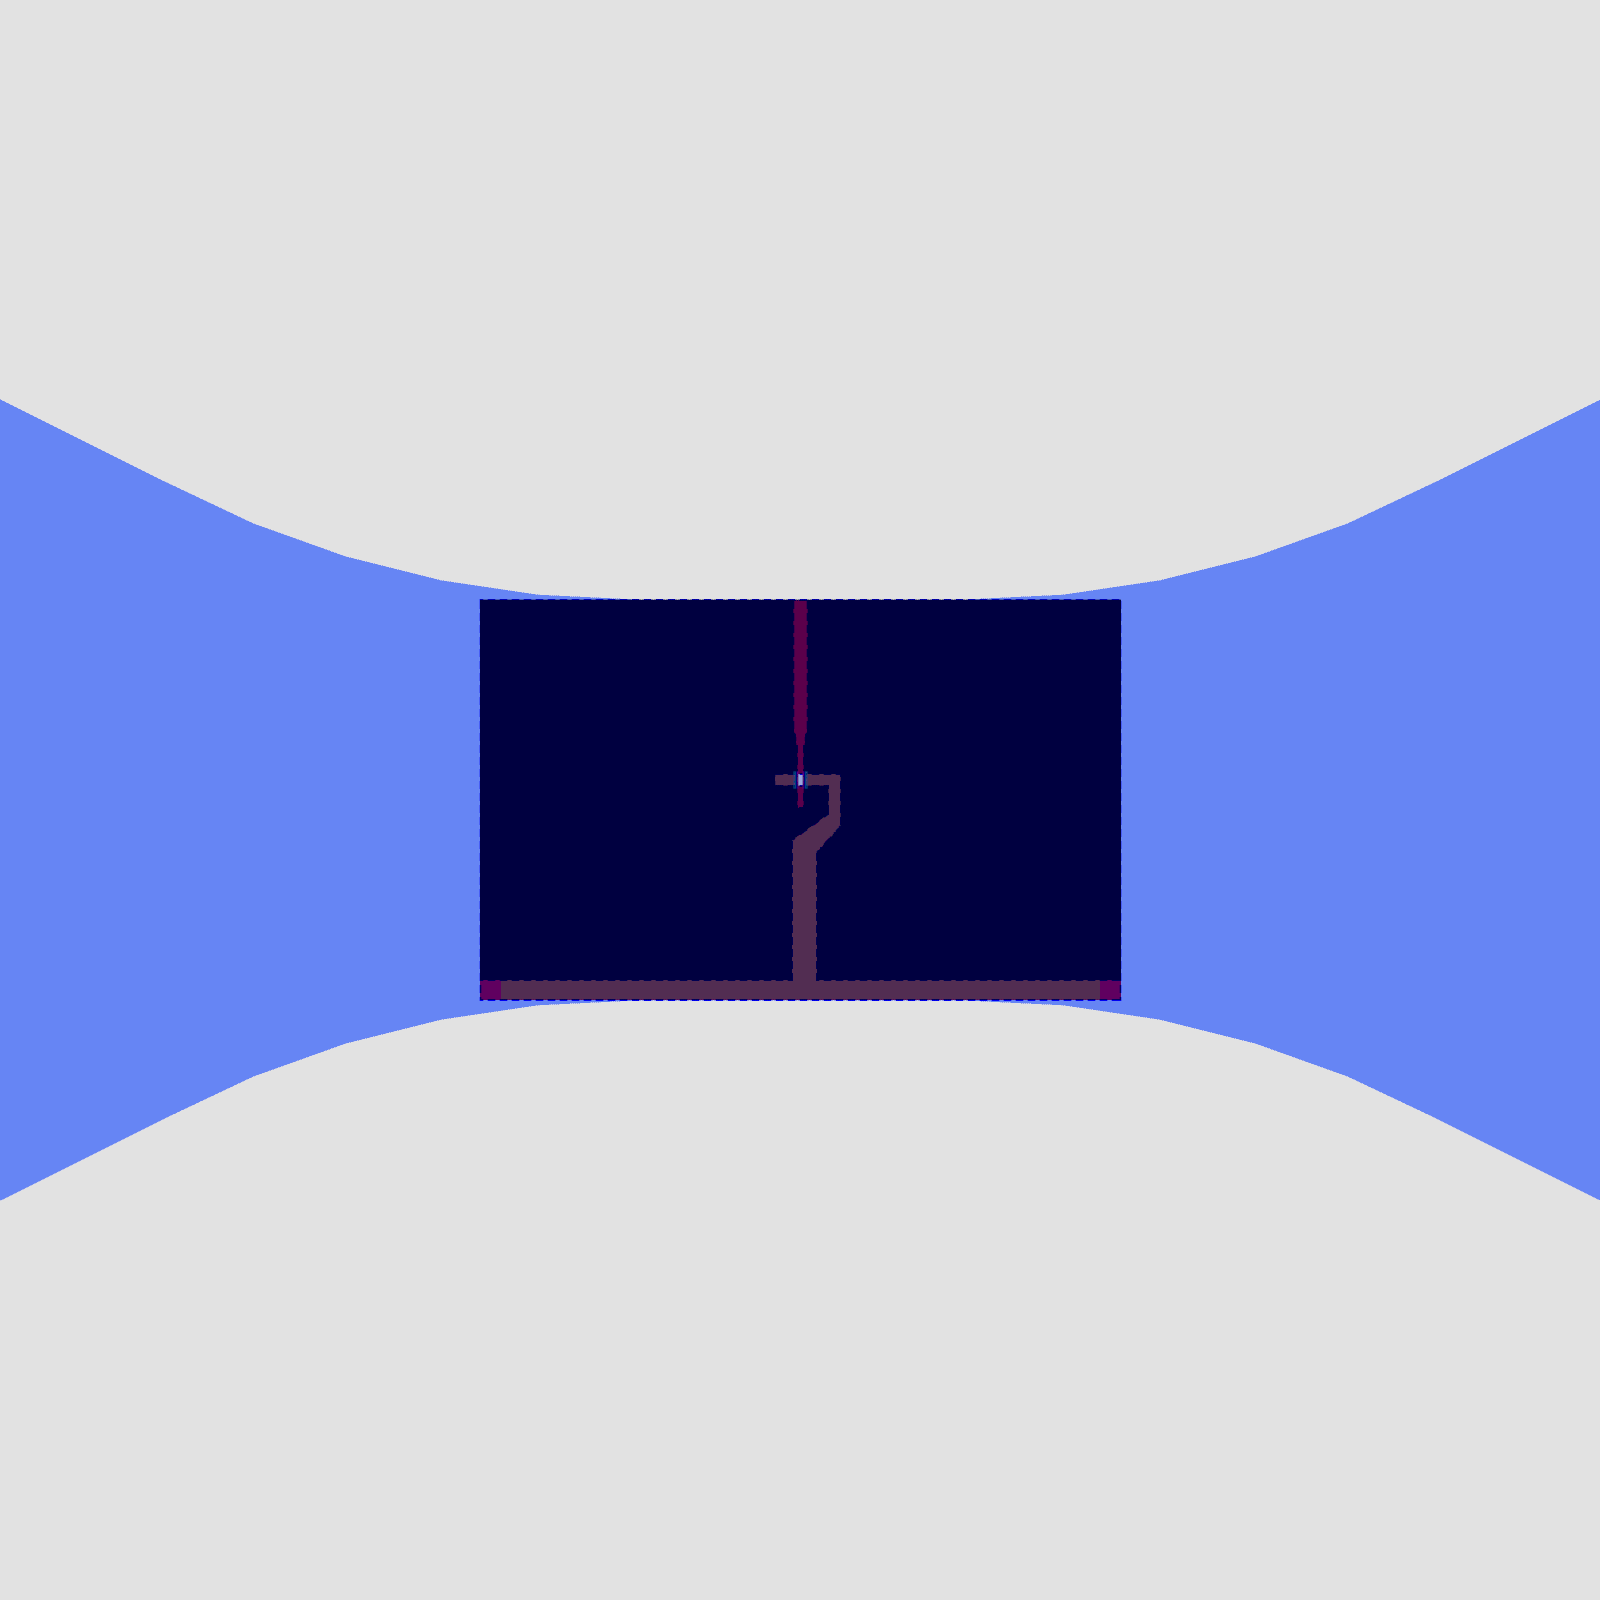

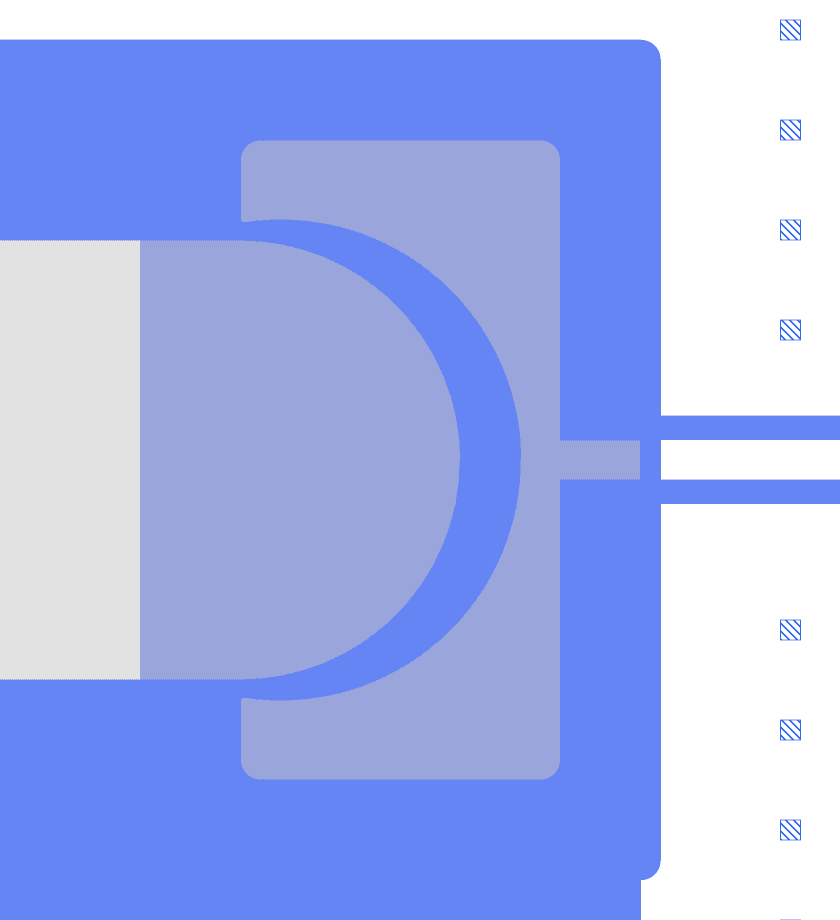

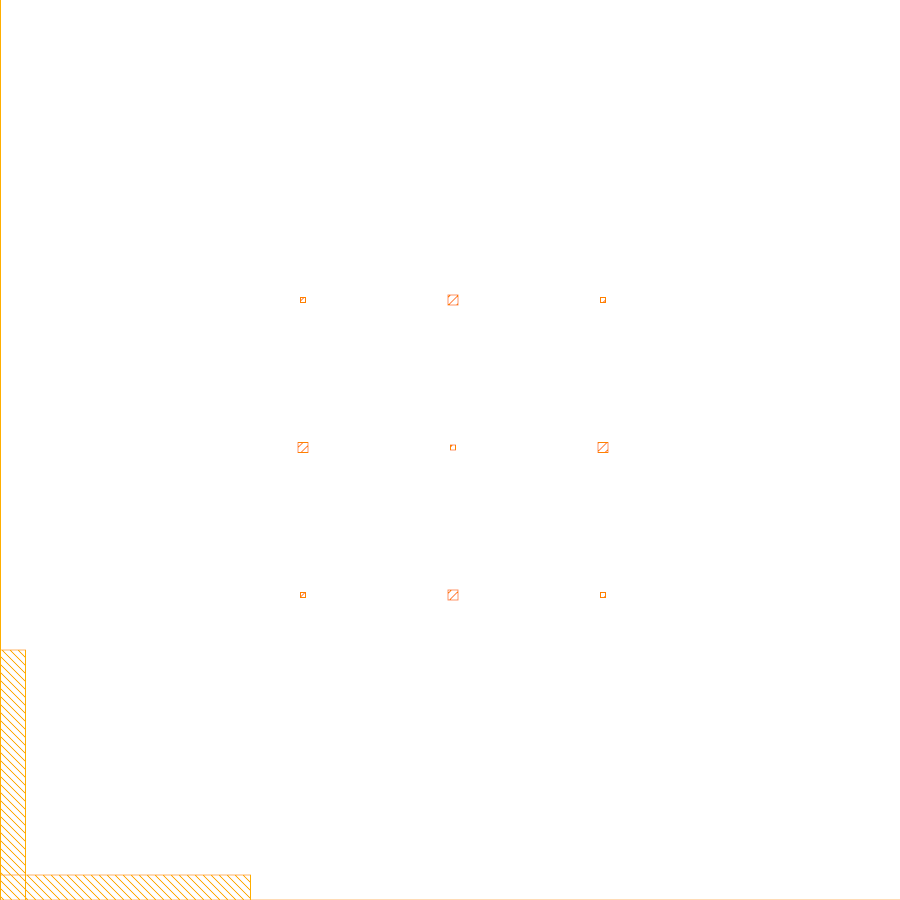

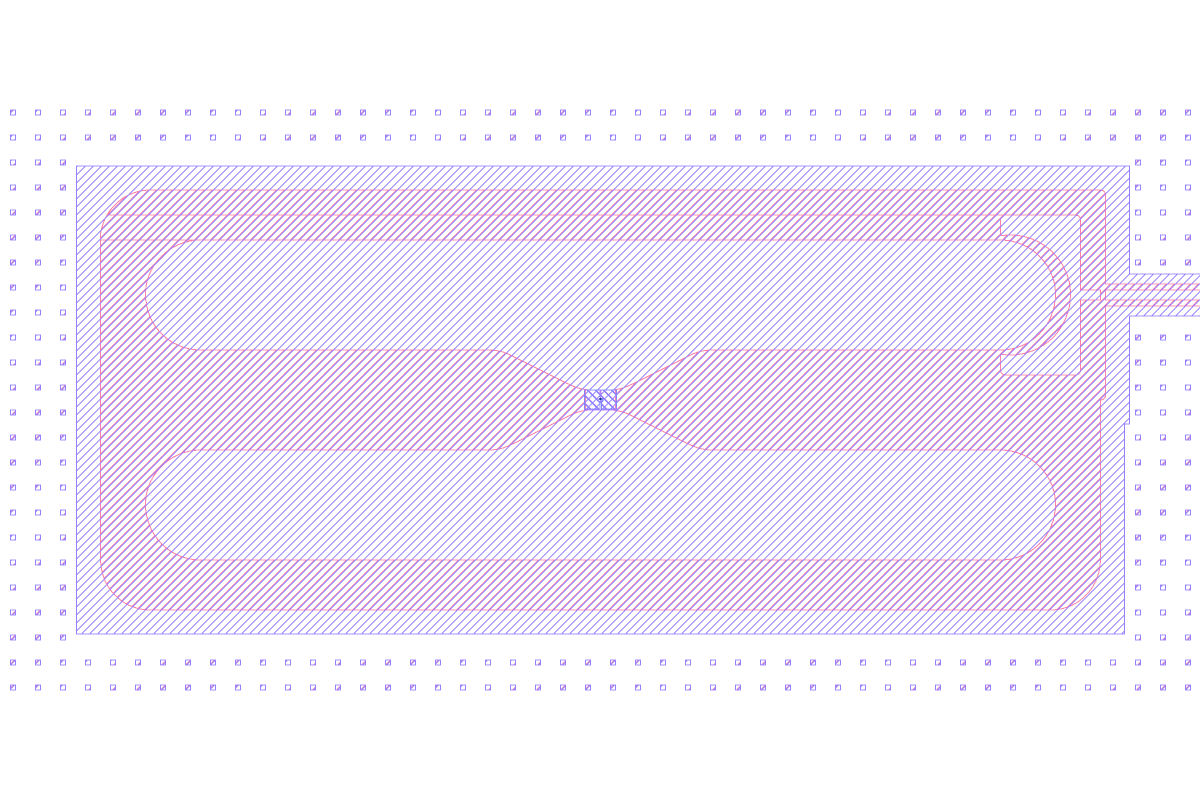

In [18]:
qx, qy = d.data["instances"]["Q1"]["place"]["at"]          # Q1 after centring
cx = qx + 1250                                              # centre of the source's chip area
show_snapshot(d, OUT / "2_transmons_wres_comp.png", box=(cx - 2500, qy - 1000, cx + 2500, qy + 1000), size=(1800, 720), width=720)
show_snapshot(d, OUT / "2_transmons_wres_comp_q1.png", box=(qx - 550, qy - 300, qx + 650, qy + 400), size=(1200, 700), width=480)
show_snapshot(d, OUT / "2_transmons_wres_comp_jj.png", box=(qx - 40, qy - 40, qx + 40, qy + 40), width=300)
show_snapshot(d, OUT / "2_transmons_wres_comp_cap.png", box=(qx + 340, qy - 10, qx + 550, qy + 220), size=(840, 920), width=320)
show_snapshot(d, OUT / "2_transmons_wres_comp_frame.png", box=(-1250, -2750, -350, -1850), size=(900, 900), width=300)
snap_file(Path("build") / "2_transmons_wres_comp_fab.oas", OUT / "2_transmons_wres_comp_fab_q1.png",
          box=(qx - 600, qy - 400, qx + 600, qy + 400), size=(1200, 800), width=480);

## 15 · Summary

| | |
|---|---|
| **matches the source** | both `TransmonTaperedInsets` and semicircle capacitors with the source options and relative positions; the 8960 µm λ/2 bus (8870 µm between our ports); the stated targets; the C-matrix sim group |
| **differs (PDK)** | the 7.5 mm Quantcore die with its frame; content centred (200 µm west of the source's own placement); sapphire; Quantcore trilayer junctions sized for 4.5 GHz (R_n ≈ 66 kΩ); the PDK cheese band in the mask |
| **changed / estimated** | `chrgln_pin_y_offset` +10 µm (−10 overlaps the pad); analytic LOM capacitances (larger than the source's Palace values) |
| **pads** | none in the source: nothing for the pad rule (100 µm) |
| **PDK design warnings** | `pdk_rn` on Q1 and Q2 (≈ 66 kΩ, sized for the stated 4.5 GHz) |
| **FEM** | a Q3D C-matrix and an eigenmode / EPR job exported to `build/jobs/2_transmons_wres_comp_ALL_*`, not solved here (junction-port limit above) |